In [1]:
# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# STEP 2: Load the Adult Income Dataset

df = pd.read_csv("adult.csv")

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

print("\nFirst 5 rows of the dataset:")

display(df.head())

Dataset loaded successfully!
Dataset Shape: (48842, 15)

First 5 rows of the dataset:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
# STEP 3: Check Dataset Information

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Size:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB

Column Names:
['age', 'workclass', 'fnlwgt', 'educatio

In [4]:
# STEP 4: Identify missing values

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nChecking '?' values in the dataset:")
print((df == "?").sum())

print("\nTotal '?' values:")
print((df == "?").sum().sum())

Missing Values Before Cleaning:
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Checking '?' values in the dataset:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

Total '?' values:
6465


In [5]:
# STEP 5: Identify duplicate records

print("Total Rows Before Duplicate Removal:", df.shape[0])

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Total Rows After Duplicate Removal:", df.shape[0])

print("Remaining Duplicate Records:", df.duplicated().sum())

Total Rows Before Duplicate Removal: 48842
Number of Duplicate Records: 52
Total Rows After Duplicate Removal: 48790
Remaining Duplicate Records: 0


Income Class Distribution:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Income Class Distribution (%):
income
<=50K    76.058619
>50K     23.941381
Name: proportion, dtype: float64


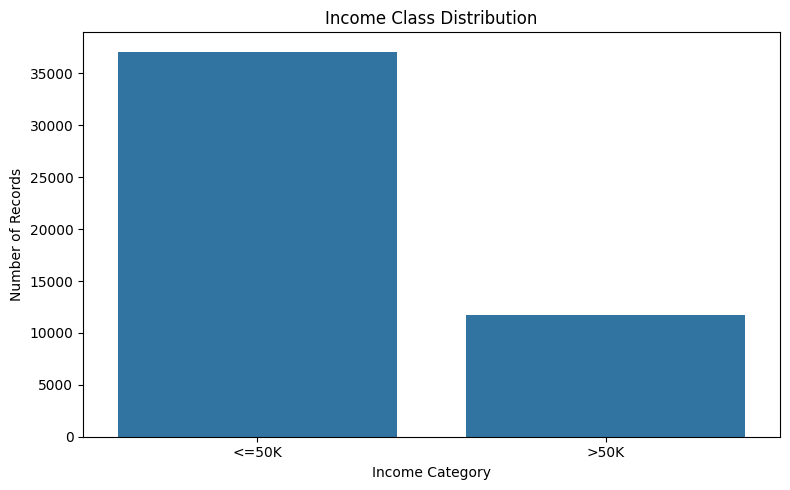

In [6]:
# STEP 6: Examine Class Distribution

print("Income Class Distribution:")
print(df["income"].value_counts())

print("\nIncome Class Distribution (%):")
print(df["income"].value_counts(normalize=True) * 100)

# Visualize class distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="income")

plt.title("Income Class Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [7]:
# STEP 7: Convert '?' values to NaN

df = df.replace("?", np.nan)

print("Missing Values After Conversion:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDataset Shape:")
print(df.shape)

Missing Values After Conversion:
age                   0
workclass          2795
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2805
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      856
income                0
dtype: int64

Total Missing Values:
6456

Dataset Shape:
(48790, 15)


In [8]:
# STEP 8: Train-Test Split (80:20)

from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df.drop("income", axis=1)
y = df["income"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed Successfully!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Train-Test Split Completed Successfully!

Training Data Shape: (39032, 14)
Testing Data Shape: (9758, 14)

Training Target Distribution:
income
<=50K    76.058106
>50K     23.941894
Name: proportion, dtype: float64

Testing Target Distribution:
income
<=50K    76.060668
>50K     23.939332
Name: proportion, dtype: float64


In [9]:
# STEP 9: Data Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing Pipeline Created Successfully!")

Numerical Features: ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']

Preprocessing Pipeline Created Successfully!


In [10]:
# STEP 10: Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [11]:
# STEP 11: Evaluate Logistic Regression Model

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Predict using test data
y_pred_logistic = logistic_model.predict(X_test)

# Get probability of income >50K
positive_class_index = list(
    logistic_model.classes_
).index(">50K")

y_prob_logistic = logistic_model.predict_proba(X_test)[
    :, positive_class_index
]

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

logistic_auc = roc_auc_score(
    (y_test == ">50K").astype(int),
    y_prob_logistic
)

logistic_precision = precision_score(
    y_test, y_pred_logistic, pos_label=">50K"
)

logistic_recall = recall_score(
    y_test, y_pred_logistic, pos_label=">50K"
)

logistic_f1 = f1_score(
    y_test, y_pred_logistic, pos_label=">50K"
)

logistic_mcc = matthews_corrcoef(
    y_test, y_pred_logistic
)

# Display results
print("Logistic Regression Evaluation Results")
print("--------------------------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("AUC      :", round(logistic_auc, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("MCC      :", round(logistic_mcc, 4))

Logistic Regression Evaluation Results
--------------------------------------
Accuracy : 0.8477
AUC      : 0.902
Precision: 0.7258
Recall   : 0.5848
F1 Score : 0.6477
MCC      : 0.5572


In [12]:
# STEP 12: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=10,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [13]:
# STEP 13: Evaluate Decision Tree Classifier

# Predict using test data
y_pred_tree = decision_tree_model.predict(X_test)

# Get probability of income >50K
positive_class_index_tree = list(
    decision_tree_model.classes_
).index(">50K")

y_prob_tree = decision_tree_model.predict_proba(X_test)[
    :, positive_class_index_tree
]

# Calculate evaluation metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_auc = roc_auc_score(
    (y_test == ">50K").astype(int),
    y_prob_tree
)

tree_precision = precision_score(
    y_test, y_pred_tree, pos_label=">50K"
)

tree_recall = recall_score(
    y_test, y_pred_tree, pos_label=">50K"
)

tree_f1 = f1_score(
    y_test, y_pred_tree, pos_label=">50K"
)

tree_mcc = matthews_corrcoef(
    y_test, y_pred_tree
)

# Display results
print("Decision Tree Evaluation Results")
print("--------------------------------")
print("Accuracy :", round(tree_accuracy, 4))
print("AUC      :", round(tree_auc, 4))
print("Precision:", round(tree_precision, 4))
print("Recall   :", round(tree_recall, 4))
print("F1 Score :", round(tree_f1, 4))
print("MCC      :", round(tree_mcc, 4))

Decision Tree Evaluation Results
--------------------------------
Accuracy : 0.8545
AUC      : 0.9001
Precision: 0.7553
Recall   : 0.5801
F1 Score : 0.6562
MCC      : 0.5738


In [14]:
# STEP 14: K-Nearest Neighbors (KNN) Classifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create KNN pipeline
knn_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        n_jobs=-1
    ))
])

# Train the KNN model
knn_model.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [15]:
# STEP 15: Evaluate KNN Classifier

# Predict using test data
y_pred_knn = knn_model.predict(X_test)

# Get probability of income >50K
positive_class_index_knn = list(
    knn_model.classes_
).index(">50K")

y_prob_knn = knn_model.predict_proba(X_test)[
    :, positive_class_index_knn
]

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_auc = roc_auc_score(
    (y_test == ">50K").astype(int),
    y_prob_knn
)

knn_precision = precision_score(
    y_test, y_pred_knn, pos_label=">50K"
)

knn_recall = recall_score(
    y_test, y_pred_knn, pos_label=">50K"
)

knn_f1 = f1_score(
    y_test, y_pred_knn, pos_label=">50K"
)

knn_mcc = matthews_corrcoef(
    y_test, y_pred_knn
)

# Display results
print("KNN Evaluation Results")
print("----------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("AUC      :", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("MCC      :", round(knn_mcc, 4))

KNN Evaluation Results
----------------------
Accuracy : 0.8316
AUC      : 0.8559
Precision: 0.6628
Recall   : 0.604
F1 Score : 0.632
MCC      : 0.5241


In [16]:
# STEP 16: Train Gaussian Naive Bayes Classifier

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from scipy import sparse

# Convert sparse matrices into dense arrays
def convert_to_dense(X):
    if sparse.issparse(X):
        return X.toarray()
    return X

# Create Naive Bayes pipeline
naive_bayes_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("to_dense", FunctionTransformer(convert_to_dense)),
    ("classifier", GaussianNB())
])

# Train the model
naive_bayes_model.fit(X_train, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [17]:
# STEP 17: Evaluate Naive Bayes Classifier

# Predict using test data
y_pred_nb = naive_bayes_model.predict(X_test)

# Get probability of income >50K
positive_class_index_nb = list(
    naive_bayes_model.classes_
).index(">50K")

y_prob_nb = naive_bayes_model.predict_proba(X_test)[
    :, positive_class_index_nb
]

# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_auc = roc_auc_score(
    (y_test == ">50K").astype(int),
    y_prob_nb
)

nb_precision = precision_score(
    y_test, y_pred_nb, pos_label=">50K"
)

nb_recall = recall_score(
    y_test, y_pred_nb, pos_label=">50K"
)

nb_f1 = f1_score(
    y_test, y_pred_nb, pos_label=">50K"
)

nb_mcc = matthews_corrcoef(
    y_test, y_pred_nb
)

# Display results
print("Naive Bayes Evaluation Results")
print("--------------------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("AUC      :", round(nb_auc, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("MCC      :", round(nb_mcc, 4))

Naive Bayes Evaluation Results
--------------------------------
Accuracy : 0.6173
AUC      : 0.8329
Precision: 0.3777
Recall   : 0.9242
F1 Score : 0.5363
MCC      : 0.3855


In [18]:
# STEP 18: Train Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [19]:
# STEP 19: Evaluate Random Forest Classifier

# Predict using test data
y_pred_rf = random_forest_model.predict(X_test)

# Get probability of income >50K
positive_class_index_rf = list(
    random_forest_model.classes_
).index(">50K")

y_prob_rf = random_forest_model.predict_proba(X_test)[
    :, positive_class_index_rf
]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_auc = roc_auc_score(
    (y_test == ">50K").astype(int),
    y_prob_rf
)

rf_precision = precision_score(
    y_test, y_pred_rf, pos_label=">50K"
)

rf_recall = recall_score(
    y_test, y_pred_rf, pos_label=">50K"
)

rf_f1 = f1_score(
    y_test, y_pred_rf, pos_label=">50K"
)

rf_mcc = matthews_corrcoef(
    y_test, y_pred_rf
)

# Display results
print("Random Forest Evaluation Results")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("AUC      :", round(rf_auc, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("MCC      :", round(rf_mcc, 4))

Random Forest Evaluation Results
--------------------------------
Accuracy : 0.8583
AUC      : 0.9139
Precision: 0.7818
Recall   : 0.5659
F1 Score : 0.6566
MCC      : 0.582


In [20]:
# STEP 20: Model Comparison Table

comparison_df = pd.DataFrame({
    "ML Model Name": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        knn_accuracy,
        nb_accuracy,
        rf_accuracy
    ],

    "AUC": [
        logistic_auc,
        tree_auc,
        knn_auc,
        nb_auc,
        rf_auc
    ],

    "Precision": [
        logistic_precision,
        tree_precision,
        knn_precision,
        nb_precision,
        rf_precision
    ],

    "Recall": [
        logistic_recall,
        tree_recall,
        knn_recall,
        nb_recall,
        rf_recall
    ],

    "F1": [
        logistic_f1,
        tree_f1,
        knn_f1,
        nb_f1,
        rf_f1
    ],

    "MCC": [
        logistic_mcc,
        tree_mcc,
        knn_mcc,
        nb_mcc,
        rf_mcc
    ]
})

comparison_df = comparison_df.round(4)

print("Comparison of All Five Machine Learning Models")
display(comparison_df)

Comparison of All Five Machine Learning Models


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8477,0.9020,0.7258,0.5848,0.6477,0.5572
1,Decision Tree,0.8545,0.9001,0.7553,0.5801,0.6562,0.5738
2,KNN,0.8316,0.8559,0.6628,0.6040,0.6320,0.5241
3,Naive Bayes,0.6173,0.8329,0.3777,0.9242,0.5363,0.3855
4,Random Forest,0.8583,0.9139,0.7818,0.5659,0.6566,0.5820


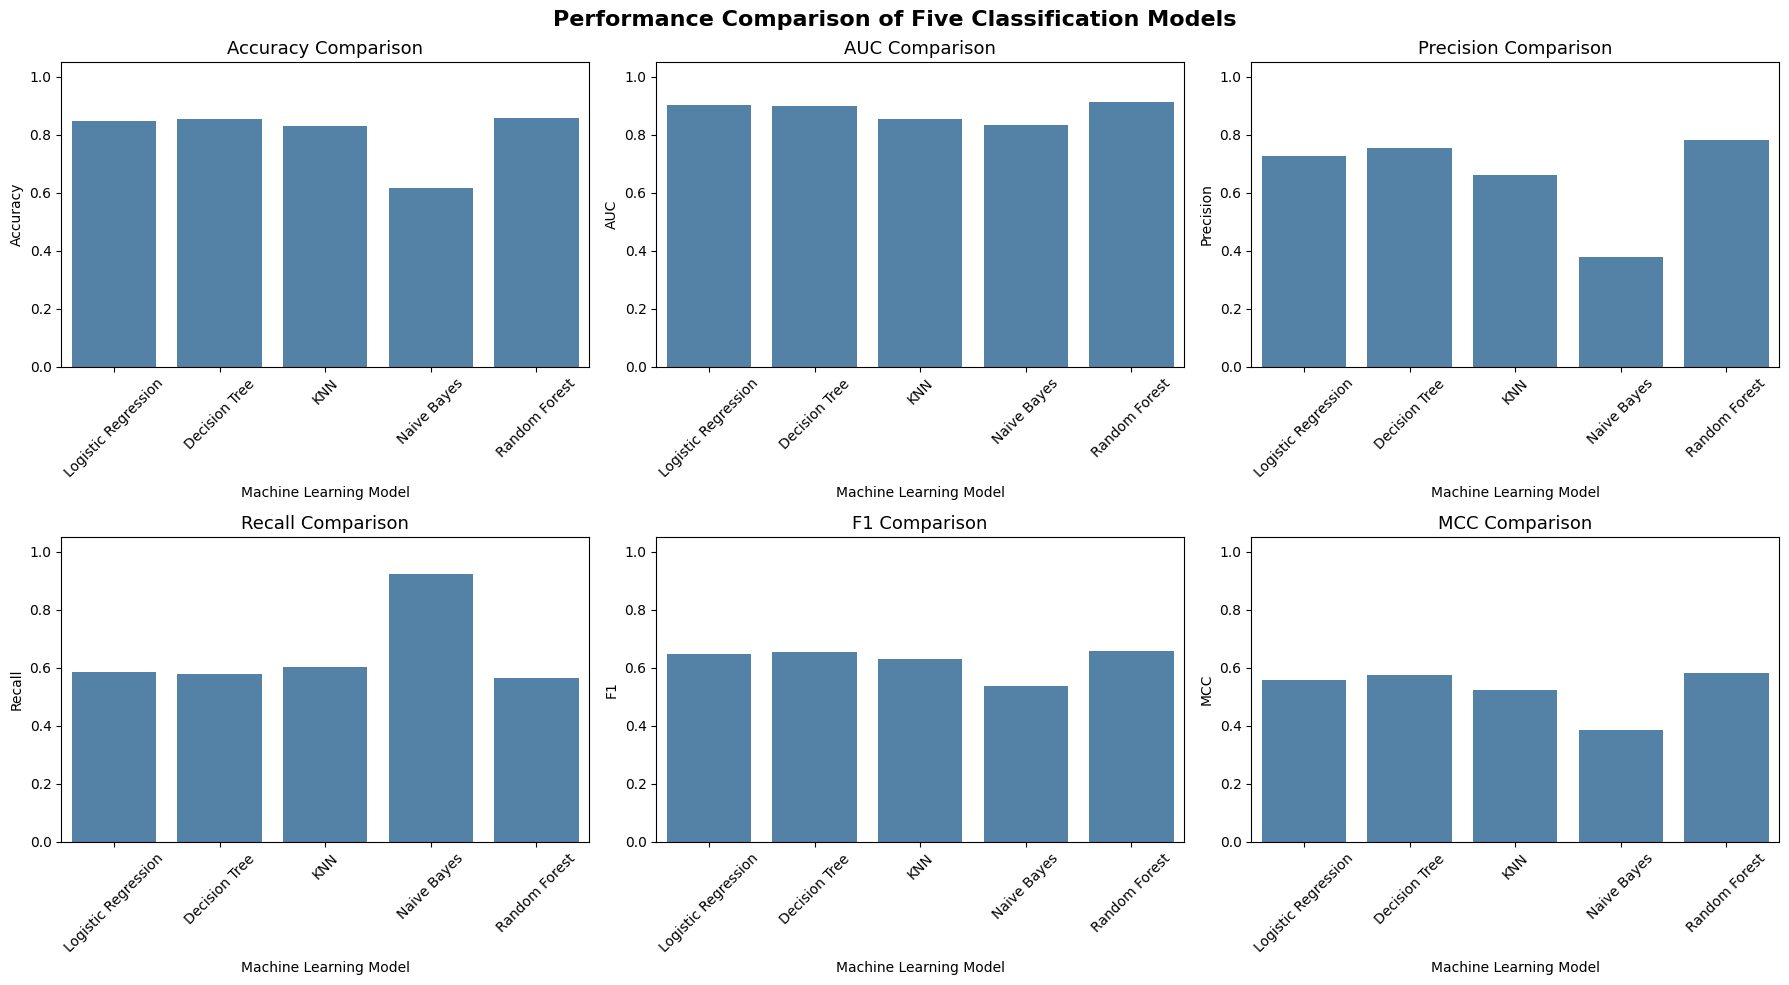

Model comparison graphs saved successfully!


In [21]:
# STEP 21: Model Performance Visualization

# Metrics to visualize
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1",
    "MCC"
]

# Create six graphs
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, metric in enumerate(metrics):

    sns.barplot(
        data=comparison_df,
        x="ML Model Name",
        y=metric,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(metric + " Comparison", fontsize=13)

    axes[i].set_xlabel("Machine Learning Model")
    axes[i].set_ylabel(metric)

    axes[i].tick_params(axis="x", rotation=45)

    axes[i].set_ylim(0, 1.05)

plt.suptitle(
    "Performance Comparison of Five Classification Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# Save graph
plt.savefig(
    "model_comparison_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison graphs saved successfully!")

In [22]:
# STEP 22: Model Performance Observations

observations = {
    "ML Model Name": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "Random Forest",
        "Overall Winner"
    ],

    "Observation about Model Performance": [
        "Achieved 84.77% accuracy and 0.9020 AUC. "
        "Provides good overall classification performance, "
        "but recall is relatively moderate.",

        "Achieved 85.45% accuracy with an F1 score of 0.6562. "
        "Performed slightly better than Logistic Regression "
        "in accuracy, precision, F1, and MCC.",

        "Achieved 83.15% accuracy and 0.6040 recall. "
        "Identified more high-income individuals than "
        "Logistic Regression and Decision Tree, but with lower precision.",

        "Achieved the highest recall of 0.9242, "
        "but the lowest accuracy of 61.73%. "
        "Its low precision indicates many false positives.",

        "Achieved the highest accuracy of 85.83%, "
        "AUC of 0.9139, precision of 0.7818, "
        "and MCC of 0.5820. It provides strong overall performance.",

        "Random Forest is selected as the overall winner "
        "because it achieved the highest accuracy, AUC, "
        "precision, and MCC, with a competitive F1 score. "
        "However, its recall is lower than that of other models."
    ]
}

observations_df = pd.DataFrame(observations)

print("Model Performance Observations")
display(observations_df)

Model Performance Observations


,ML Model Name,Observation about Model Performance
0,Logistic Regression,Achieved 84.77% accuracy and 0.9020 AUC. Provi...
1,Decision Tree,Achieved 85.45% accuracy with an F1 score of 0...
2,KNN,Achieved 83.15% accuracy and 0.6040 recall. Id...
3,Naive Bayes,"Achieved the highest recall of 0.9242, but the..."
4,Random Forest,"Achieved the highest accuracy of 85.83%, AUC o..."
5,Overall Winner,Random Forest is selected as the overall winne...


In [23]:
# STEP 23: Save Test Data and Evaluation Results

# Save test dataset with actual income labels
test_data = X_test.copy()
test_data["income"] = y_test

test_data.to_csv("test_data.csv", index=False)

# Save model evaluation metrics
comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

# Save model performance observations
observations_df.to_csv(
    "model_observations.csv",
    index=False
)

print("Files saved successfully!")
print("1. test_data.csv")
print("2. model_comparison_results.csv")
print("3. model_observations.csv")

Files saved successfully!
1. test_data.csv
2. model_comparison_results.csv
3. model_observations.csv


In [24]:
# STEP 24: Save All Five Trained Models

import os
import joblib

# Create model folder
os.makedirs("model", exist_ok=True)

# Save trained models
joblib.dump(logistic_model, "model/logistic_regression.pkl")

joblib.dump(decision_tree_model, "model/decision_tree.pkl")

joblib.dump(knn_model, "model/knn.pkl")

joblib.dump(naive_bayes_model, "model/naive_bayes.pkl")

joblib.dump(random_forest_model, "model/random_forest.pkl")

print("All five trained models saved successfully!")

print("\nFiles inside model folder:")
print(os.listdir("model"))

All five trained models saved successfully!

Files inside model folder:
['decision_tree.pkl', 'knn.pkl', 'logistic_regression.pkl', 'naive_bayes.pkl', 'random_forest.pkl']


In [25]:
# STEP 25: Create requirements.txt

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
scipy
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully!")

print("\nFile contents:")
with open("requirements.txt", "r") as file:
    print(file.read())

requirements.txt created successfully!

File contents:
pandas
numpy
matplotlib
seaborn
scikit-learn
scipy
joblib

